# 02 · Graphs with `anemoi-graphs`

**AIWCAS 2026 · Anemoi hands-on · about 15 minutes**

In notebook 01 you saw that an anemoi dataset stores its gridpoints as flat 1-D `latitudes` and `longitudes` arrays: no image, just a list of points on the sphere. An Anemoi model works on exactly that: a **graph** whose nodes are points on the sphere and whose edges say who passes messages to whom. `anemoi-graphs` builds that graph from a short YAML recipe.

By the end of this notebook you will be able to:

1. explain the **encoder–processor–decoder** graph and *why* it looks the way it does,
2. read and write a **graph recipe**, and build it with the **CLI** and the **Python API**,
3. **inspect** the resulting `torch_geometric` `HeteroData` object (counts, attributes, degrees, edge lengths),
4. **visualise** it, including anemoi-graphs' interactive 3D globe.

| Section | Minutes |
|---|---|
| 1 · The encoder–processor–decoder graph | 2 |
| 2 · The recipe | 2 |
| 3 · Build it (CLI + Python) | 2 |
| 4 · Look inside the `HeteroData` | 2 |
| 5 · Maps | 2.5 |
| 6 · Interactive and 3D views | 2 |
| 7 · Try it (2 exercises) | 2.5 |

## 1 · The encoder–processor–decoder graph

![Encoder–processor–decoder graph](figures/02_encoder_processor_decoder.svg)

| Piece | What it is | In our recipe |
|---|---|---|
| **data nodes** | one node per gridpoint of the dataset | the O96 grid of the dataset, 40 320 nodes |
| **hidden nodes** | a coarser mesh where most of the computation happens | a refined icosahedron (`TriNodes`), 10 242 nodes |
| **encoder edges** | data → hidden: each hidden node gathers the gridpoints around it | `CutOffEdges` (all data nodes within a radius) |
| **processor edges** | hidden → hidden: message passing on the mesh, repeated over several layers | `MultiScaleEdges` |
| **decoder edges** | hidden → data: each gridpoint reads back from nearby hidden nodes | `KNNEdges`, k = 3 |

**Why a coarser hidden mesh?** The cost of a message-passing step scales with the number of nodes and edges, so working on about 4× fewer nodes is about 4× cheaper. And each hop on a coarse mesh covers more distance, so information travels further per layer (a larger *receptive field*).

**Why a multi-scale mesh?** A 6-hour forecast needs information from thousands of kilometres away. On a mesh with only short edges that takes dozens of hops. `MultiScaleEdges` adds the edges of every coarser refinement level of the icosahedron (levels 1…5), so long-range "highways" exist next to local edges. In section 5 you will count the hops.

**Why graphs at all?** Nothing above assumes a regular lat-lon image. Any set of points works: reduced Gaussian grids (like O96 here), a limited-area model (LAM) domain, a stretched grid that is fine over a region and coarse elsewhere, or observation locations. Training ships ready-made recipes for these cases (`limited_area.yaml`, `stretched_grid.yaml`, …).

### Setup

Paths are collected in one place. `DATASET` points at the O96 dataset from notebook 01; set the environment variable `AIWCAS_DATASET` to use another one. Graph outputs go to `$SCRATCH/aiwcas26/graphs/`, not into the repository.

> ⏱️ The first `import` of torch and anemoi takes up to a minute on a login node (the venv lives on a parallel filesystem). Building the graphs afterwards takes seconds.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="Consider using IPython.display.IFrame")

import logging
import os
import subprocess
import sys
import time
from pathlib import Path

import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import plotly.io as pio
import torch
import yaml
from matplotlib.collections import LineCollection

from anemoi.graphs.create import GraphCreator
from anemoi.utils.config import DotDict

logging.getLogger("anemoi").setLevel(logging.ERROR)  # keep the build logs quiet
pio.renderers.default = "plotly_mimetype+notebook_connected"  # inline plotly in JupyterLab and VS Code

DATA_DIR = Path(os.environ.get("WORK", "/leonardo_work/tra26_aiwcas")) / "a08trd25" / "data"
DATASET = Path(os.environ.get(
    "AIWCAS_DATASET",
    DATA_DIR / "anemoi" / "aifs-ea-an-oper-0001-mars-o96-2017-2017-6h-v8-testing.zarr",
))
RECIPE = Path("configs/02_graph_recipe.yaml")
OUT = Path(os.environ["SCRATCH"]) / "aiwcas26" / "graphs"
OUT.mkdir(parents=True, exist_ok=True)

cartopy.config["pre_existing_data_dir"] = str(DATA_DIR / "cartopy")  # coastlines without downloading

# Colours used in every plot: data = blue, hidden = orange
C_DATA, C_HIDDEN, C_EDGE = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 10})
def data_node_builder(zarr_path, octahedral_n=96):
    # Data nodes from an anemoi dataset; if it is missing, compute the octahedral grid O<n> itself (no download)
    if Path(zarr_path).exists():
        return {"_target_": "anemoi.graphs.nodes.AnemoiDatasetNodes", "dataset": str(zarr_path)}
    lat = np.rad2deg(np.arcsin(np.polynomial.legendre.leggauss(2 * octahedral_n)[0]))[::-1]
    nlon = [20 + 4 * i for i in range(octahedral_n)]
    nlon += nlon[::-1]
    npz = OUT / f"o{octahedral_n}_grid.npz"
    np.savez(npz, latitudes=np.repeat(lat, nlon), longitudes=np.concatenate([np.arange(k) * 360 / k for k in nlon]))
    print(f"{zarr_path} not found: using the analytic O{octahedral_n} grid in {npz}")
    return {"_target_": "anemoi.graphs.nodes.NPZFileNodes", "npz_file": str(npz)}

print("dataset:", DATASET, "| exists:", DATASET.exists())
print("outputs:", OUT)

dataset: /leonardo_work/tra26_aiwcas/a08trd25/data/anemoi/aifs-ea-an-oper-0001-mars-o96-2017-2017-6h-v8-testing.zarr | exists: True
outputs: /leonardo_scratch/large/usertrain/a08trd25/aiwcas26/graphs


## 2 · The recipe

A recipe has two main sections:

- **`nodes`**: named node sets. Each has a `node_builder` (where the coordinates come from) and optional `attributes`.
- **`edges`**: a list of `source_name → target_name` connections. Each has one or more `edge_builders` and optional `attributes`.

Every builder is a Python class given by `_target_` and instantiated by Hydra, the same mechanism anemoi-training uses everywhere. This recipe mirrors anemoi-training's **default** graph config (`training/config/graph/multi_scale.yaml`), so you will recognise it in the training notebook.

In [2]:
print(RECIPE.read_text())

# Encoder-processor-decoder graph recipe for the AIWCAS 2026 graphs notebook.
# Mirrors anemoi-training's default `graph: multi_scale` config
# (src/anemoi-core/training/src/anemoi/training/config/graph/multi_scale.yaml),
# with the dataset path written out instead of interpolated from the training config.
#
# Build it with:
#   anemoi-graphs create notebooks/configs/02_graph_recipe.yaml $SCRATCH/aiwcas26/graphs/graph_cli.pt
#
# The notebook sets the `dataset:` path below from its DATASET variable.

nodes:
  # Data nodes: the gridpoints of the anemoi dataset (here O96, 40 320 points)
  data:
    node_builder:
      _target_: anemoi.graphs.nodes.AnemoiDatasetNodes
      dataset: /leonardo_work/tra26_aiwcas/a08trd25/data/anemoi/aifs-ea-an-oper-0001-mars-o96-2017-2017-6h-v8-testing.zarr
    attributes:
      area_weight:
        _target_: anemoi.graphs.nodes.attributes.SphericalAreaWeights
        norm: unit-max
        fill_value: 0

  # Hidden nodes: a refined icosahedron (resolution 5 

A few of the builders available in this version (graphs 0.9.8):

| Kind | `_target_` (all under `anemoi.graphs.`) | Use |
|---|---|---|
| data nodes | `nodes.AnemoiDatasetNodes` | lat/lon of an anemoi dataset (zarr) |
| | `nodes.LatLonNodes`, `nodes.NPZFileNodes`, `nodes.XArrayNodes`, `nodes.ReducedGaussianGridNodes` | arrays, files, named grids |
| hidden nodes | `nodes.TriNodes`, `nodes.HexNodes`, `nodes.HEALPixNodes` | refined icosahedron, H3 hexagons, HEALPix |
| | `nodes.LimitedAreaTriNodes`, `nodes.StretchedTriNodes` | LAM and stretched meshes |
| edges | `edges.KNNEdges`, `edges.CutOffEdges` | k nearest neighbours, all neighbours within a radius |
| | `edges.MultiScaleEdges`, `edges.HEALPixMultiScaleEdges` | multi-scale processor edges |
| node attributes | `nodes.attributes.SphericalAreaWeights`, `…CosineLatWeightedAttribute`, `…UniformWeights` | area weights (used in the loss) |
| | `nodes.attributes.LimitedAreaMask`, `…CutOutMask` | masks for LAM / stretched setups |
| edge attributes | `edges.attributes.EdgeLength`, `…EdgeDirection`, `…Azimuth`, `…RadialBasisFeatures` | geometric edge features fed to the model |

Two details worth knowing:

- `CutOffEdges(cutoff_factor=0.6)`: the radius is 0.6 × the largest nearest-neighbour spacing of the *target* (hidden) mesh. Exercise 2 shows why 0.6 and not smaller.
- `MultiScaleEdges(scale_resolutions=5)`: an integer means "levels 1 to 5". A list such as `[5]` means only that level.

## 3 · Build it

### 3a · With the CLI

In a terminal (or a Slurm script) you would run:

```bash
anemoi-graphs create notebooks/configs/02_graph_recipe.yaml $SCRATCH/aiwcas26/graphs/graph_cli.pt
```

Here we start exactly that command **in the background**, so it does not block the notebook (a new Python process means another slow import). We save a copy of the recipe with the `DATASET` path filled in, so the CLI and the Python API build the same graph. (If the dataset is missing, `data_node_builder` falls back to an O96 grid computed in numpy.) We look at the CLI's output in section 4.

In [3]:
recipe = yaml.safe_load(RECIPE.read_text())
recipe["nodes"]["data"]["node_builder"] = data_node_builder(DATASET, 96)
(OUT / "recipe.yaml").write_text(yaml.safe_dump(recipe, sort_keys=False))

cli_log = open(OUT / "create.log", "w")
cli = subprocess.Popen(
    [str(Path(sys.executable).parent / "anemoi-graphs"), "create", "--overwrite",
     str(OUT / "recipe.yaml"), str(OUT / "graph_cli.pt")],
    stdout=cli_log, stderr=subprocess.STDOUT,
)
print("CLI started, pid", cli.pid, "→ log in", OUT / "create.log")

CLI started, pid 493082 → log in /leonardo_scratch/large/usertrain/a08trd25/aiwcas26/graphs/create.log


### 3b · With the Python API

`GraphCreator` accepts a path to a YAML file or a config object. `create()` builds nodes, then edges, then attributes, and saves the result with `torch.save` if you give it a `save_path`. anemoi-training calls the same `GraphCreator` on its `graph:` config section when it builds a graph during training.

In [4]:
t0 = time.time()
graph = GraphCreator(DotDict(recipe)).create(save_path=OUT / "graph.pt", overwrite=True)
print(f"built in {time.time() - t0:.1f} s → {OUT / 'graph.pt'}\n")
graph

built in 18.8 s → /leonardo_scratch/large/usertrain/a08trd25/aiwcas26/graphs/graph.pt



HeteroData(
  data={
    x=[40320, 2],
    node_type='AnemoiDatasetNodes',
    area_weight=[40320, 1],
  },
  hidden={
    x=[10242, 2],
    node_type='TriNodes',
  },
  (data, to, hidden)={
    edge_index=[2, 62980],
    edge_type='CutOffEdges',
    edge_length=[62980, 1],
    edge_dirs=[62980, 2],
  },
  (hidden, to, hidden)={
    edge_index=[2, 81840],
    edge_type='MultiScaleEdges',
    edge_length=[81840, 1],
    edge_dirs=[81840, 2],
  },
  (hidden, to, data)={
    edge_index=[2, 120960],
    edge_type='KNNEdges',
    edge_length=[120960, 1],
    edge_dirs=[120960, 2],
  }
)

The result is a [`torch_geometric.data.HeteroData`](https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.data.HeteroData.html): a dictionary of node sets and edge sets.

- `graph["data"].x`: node coordinates, shape `(N, 2)`, as **(lat, lon) in radians**.
- `graph["data", "to", "hidden"].edge_index`: shape `(2, E)`. Row 0 holds the **source** node indices, row 1 the **target** node indices.
- Other keys are attributes: one row per node (`area_weight`) or per edge (`edge_length`, `edge_dirs`).

## 4 · Look inside the `HeteroData`

In [5]:
for name in graph.node_types:
    s = graph[name]
    print(f"nodes {name:7s} {s.num_nodes:>7,d}   attributes: {[k for k in s.keys() if k != 'x']}")
for src, rel, dst in graph.edge_types:
    e = graph[src, rel, dst]
    attrs = {k: tuple(v.shape) for k, v in e.items() if k != "edge_index" and torch.is_tensor(v)}
    print(f"edges {src:>6s} → {dst:6s} {e.num_edges:>7,d}   ({e.edge_type})  {attrs}")

print("\nfirst data node (lat, lon) in degrees:", np.rad2deg(graph["data"].x[0].numpy()))
print("first 3 encoder edges (source row / target row):\n", graph["data", "to", "hidden"].edge_index[:, :3])

nodes data     40,320   attributes: ['node_type', 'area_weight']
nodes hidden   10,242   attributes: ['node_type']
edges   data → hidden  62,980   (CutOffEdges)  {'edge_length': (62980, 1), 'edge_dirs': (62980, 2)}
edges hidden → hidden  81,840   (MultiScaleEdges)  {'edge_length': (81840, 1), 'edge_dirs': (81840, 2)}
edges hidden → data   120,960   (KNNEdges)  {'edge_length': (120960, 1), 'edge_dirs': (120960, 2)}

first data node (lat, lon) in degrees: [89.28422  0.     ]
first 3 encoder edges (source row / target row):
 tensor([[11, 12, 13],
        [ 0,  0,  0]], dtype=torch.int32)


The stored `edge_length` is **normalised** (`norm: unit-std`) because it is a model input. For plotting we recompute lengths in km from the coordinates. We also count the **in-degree** of each target node, i.e. how many messages it receives:

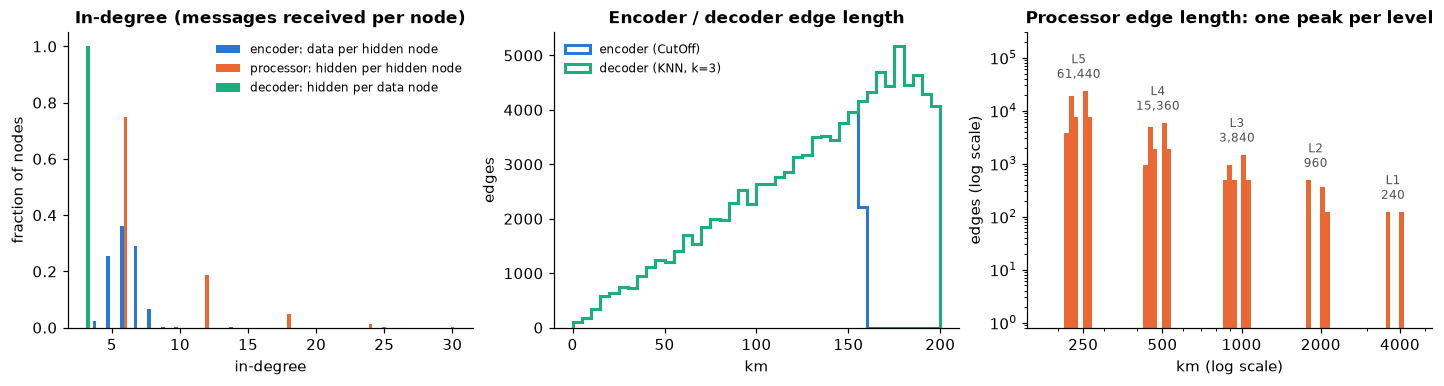

In [6]:
R_EARTH = 6371.0

def edge_lengths_km(g, src, dst):
    ei = g[src, "to", dst].edge_index.numpy()
    a, b = g[src].x.numpy()[ei[0]], g[dst].x.numpy()[ei[1]]
    h = np.sin((b[:, 0] - a[:, 0]) / 2) ** 2 + np.cos(a[:, 0]) * np.cos(b[:, 0]) * np.sin((b[:, 1] - a[:, 1]) / 2) ** 2
    return 2 * R_EARTH * np.arcsin(np.sqrt(h))

def in_degree(g, src, dst):
    return np.bincount(g[src, "to", dst].edge_index[1].numpy(), minlength=g[dst].num_nodes)

ENC, PROC, DEC = ("data", "hidden"), ("hidden", "hidden"), ("hidden", "data")
L = {k: edge_lengths_km(graph, *k) for k in (ENC, PROC, DEC)}
# MultiScaleEdges: a level-r edge is about 7054 km / 2**r long (7054 km = icosahedron edge)
level = np.rint(np.log2(7054 / L[PROC])).astype(int)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.4), constrained_layout=True)
for k, lab, col in [(ENC, "encoder: data per hidden node", C_DATA), (PROC, "processor: hidden per hidden node", C_HIDDEN),
                    (DEC, "decoder: hidden per data node", "#1baf7a")]:
    d = in_degree(graph, *k)
    vals, counts = np.unique(d, return_counts=True)
    axs[0].bar(vals + {ENC: -0.27, PROC: 0, DEC: 0.27}[k], counts / counts.sum(), width=0.27, color=col, label=lab)
axs[0].set(title="In-degree (messages received per node)", xlabel="in-degree", ylabel="fraction of nodes")
axs[0].legend(frameon=False, fontsize=8)

bins = np.linspace(0, 200, 41)
axs[1].hist(L[ENC], bins=bins, histtype="step", lw=2, color=C_DATA, label="encoder (CutOff)")
axs[1].hist(L[DEC], bins=bins, histtype="step", lw=2, color="#1baf7a", label="decoder (KNN, k=3)")
axs[1].set(title="Encoder / decoder edge length", xlabel="km", ylabel="edges")
axs[1].legend(frameon=False, fontsize=8, loc="upper left")

pbins = np.geomspace(180, 4500, 80)
axs[2].hist(L[PROC], bins=pbins, color=C_HIDDEN)
axs[2].set(xscale="log", yscale="log", title="Processor edge length: one peak per level", xlabel="km (log scale)",
           ylabel="edges (log scale)", ylim=(0.8, 3e5))
axs[2].set_xticks([250, 500, 1000, 2000, 4000], ["250", "500", "1000", "2000", "4000"])
axs[2].xaxis.set_minor_formatter(plt.NullFormatter())
for r in range(1, 6):
    m = level == r
    peak = np.histogram(L[PROC][m], bins=pbins)[0].max()
    axs[2].text(np.median(L[PROC][m]), peak * 1.5, f"L{r}\n{m.sum():,}", ha="center", va="bottom", fontsize=8, color="#52514e")
plt.show()

What to notice:

- **Decoder**: every data node receives exactly 3 messages, because KNN fixes the in-degree.
- **Encoder**: the cutoff fixes a radius (about 160 km), not a count, so hidden nodes collect between 4 and 20 data nodes depending on the local grid density.
- **Processor**: most nodes have 6 neighbours, and nodes that already existed at coarser levels have 12, 18, 24 or 30 (6 per level they belong to). The edge lengths fall into **5 clean peaks**, one per refinement level (L1 to L5, with their edge counts): the multi-scale mesh is the union of 5 meshes.

### Why area weights?

Gridpoints do not represent equal areas of the globe. `SphericalAreaWeights` computes the area of each node's spherical Voronoi cell. In training, the default loss scaler `GraphNodeAttributeScaler(nodes_attribute_name: area_weight)` (in `training/config/training/scalers/global.yaml`) weights each gridpoint's error by this attribute, so that densely sampled regions do not dominate the loss. On a regular lat-lon grid this matters a lot: the poles are heavily oversampled there.

## 5 · Maps

A small helper draws edges as great-circle arcs in any cartopy projection.

In [7]:
def edge_segments(g, src, dst, mask=None, n=8):
    # Great-circle polylines (lon, lat in degrees), one per edge
    ei = g[src, "to", dst].edge_index.numpy()
    if mask is not None:
        ei = ei[:, mask]
    def xyz(ll):
        return np.stack([np.cos(ll[:, 0]) * np.cos(ll[:, 1]), np.cos(ll[:, 0]) * np.sin(ll[:, 1]), np.sin(ll[:, 0])], -1)
    a, b = xyz(g[src].x.numpy()[ei[0]]), xyz(g[dst].x.numpy()[ei[1]])
    t = np.linspace(0, 1, n)[None, :, None]
    p = a[:, None] * (1 - t) + b[:, None] * t  # chord, then project back onto the sphere
    p /= np.linalg.norm(p, axis=-1, keepdims=True)
    return np.rad2deg(np.stack([np.arctan2(p[..., 1], p[..., 0]), np.arcsin(p[..., 2])], -1))

def add_edges(ax, segs, **kw):
    # Project polylines and drop the parts that fall off the visible map
    shp = segs.shape
    xy = ax.projection.transform_points(ccrs.PlateCarree(), segs[..., 0].ravel(), segs[..., 1].ravel())[:, :2].reshape(shp)
    ok = np.isfinite(xy).all(axis=(1, 2))
    ax.add_collection(LineCollection(xy[ok], **kw))

def lonlat(g, name):
    ll = np.rad2deg(g[name].x.numpy())
    return ll[:, 1], ll[:, 0]

def base_map(ax, land=True):
    if land:
        ax.add_feature(cfeature.LAND.with_scale("110m"), facecolor="#efeee9", edgecolor="none", zorder=0)
    ax.coastlines("110m", color="#9b9a95", linewidth=0.5)

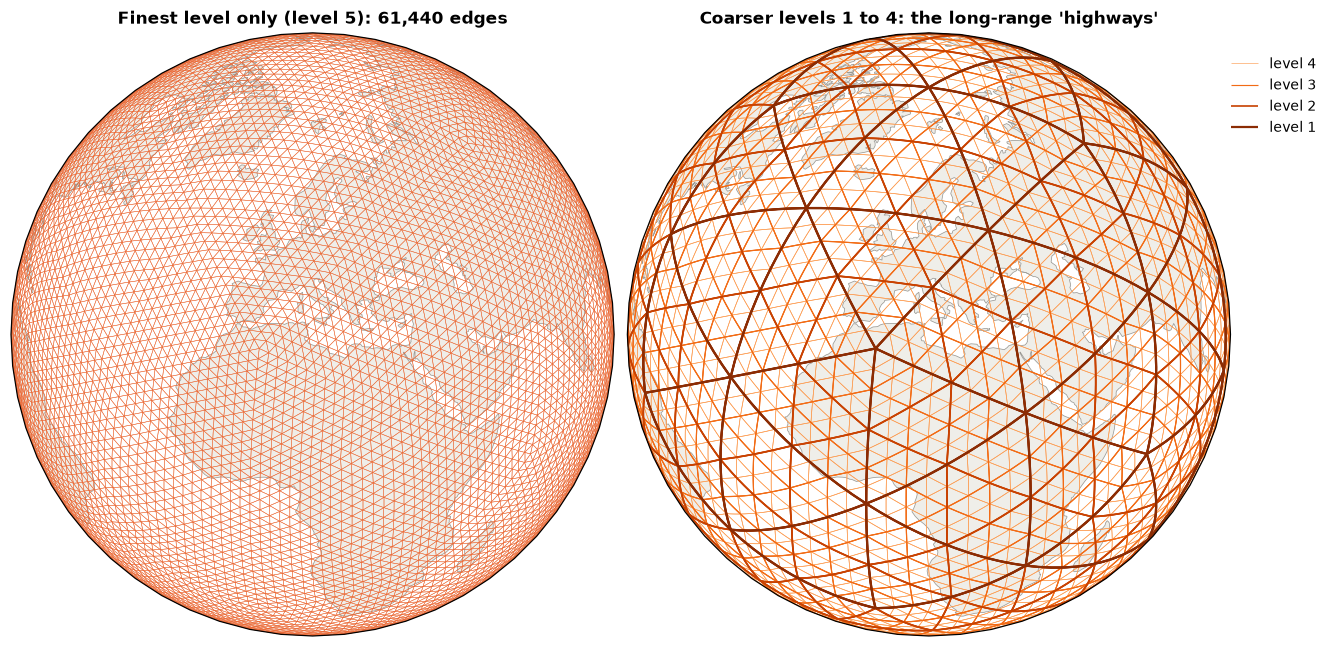

In [8]:
proj = ccrs.Orthographic(central_longitude=12, central_latitude=35)
fig, axs = plt.subplots(1, 2, figsize=(12, 6), subplot_kw={"projection": proj}, constrained_layout=True)
hlon, hlat = lonlat(graph, "hidden")

ax = axs[0]
ax.set_global(); base_map(ax)
add_edges(ax, edge_segments(graph, *PROC, mask=level == 5, n=2), colors=C_HIDDEN, linewidths=0.3)
ax.set_title(f"Finest level only (level 5): {(level == 5).sum():,} edges")

ax = axs[1]
ax.set_global(); base_map(ax)
cmap = plt.get_cmap("Oranges")
for r in (4, 3, 2, 1):
    add_edges(ax, edge_segments(graph, *PROC, mask=level == r, n=12), colors=[cmap(0.45 + 0.17 * (4 - r))],
              linewidths=0.4 + 0.35 * (4 - r), label=f"level {r}")
ax.set_title("Coarser levels 1 to 4: the long-range 'highways'")
ax.legend(loc="upper left", bbox_to_anchor=(0.98, 0.98), frameon=False, fontsize=9)
plt.show()

**How many hops does it take to cross the globe?** Breadth-first search from one hidden node, first using only the finest edges and then using all levels:

In [9]:
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path

ei, n = graph[PROC].edge_index.numpy(), graph["hidden"].num_nodes
for lab, m in [("finest level only", level == 5), ("multi-scale (levels 1-5)", np.ones_like(level, bool))]:
    A = sp.csr_matrix((np.ones(m.sum()), (ei[0, m], ei[1, m])), shape=(n, n))
    hops = shortest_path(A, unweighted=True, indices=0)
    print(f"{lab:26s}: every hidden node is reached within {int(hops.max()):3d} hops")

finest level only         : every hidden node is reached within  80 hops
multi-scale (levels 1-5)  : every hidden node is reached within   8 hops


With 16 processor layers (the default GNN, `num_layers: 16`), a single-level mesh could only see about a fifth of the way around the globe. The multi-scale mesh can see all of it. This is the GraphCast / AIFS design.

Next, zoom in on northern Italy, around FBK in Trento, to see how the **encoder** and the **decoder** connect the two node sets.

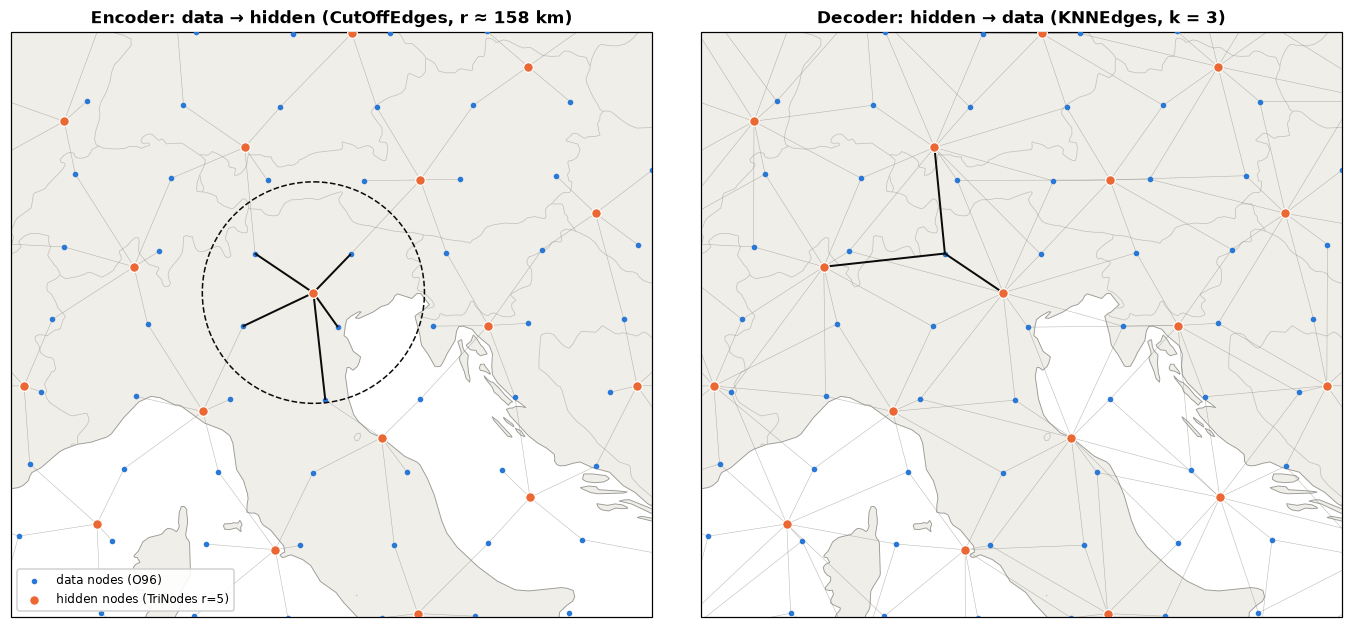

highlighted hidden node near Trento receives 5 encoder edges; the data node in Trento receives 3 decoder edges


In [10]:
TRENTO = (11.12, 46.07)  # lon, lat
extent = [6.5, 17.5, 41.5, 49]
dlon, dlat = lonlat(graph, "data")

# the hidden node closest to Trento and the encoder edges that end in it
d2 = (hlon - TRENTO[0]) ** 2 + (hlat - TRENTO[1]) ** 2
h0 = int(np.argmin(d2))
enc_ei = graph[ENC].edge_index.numpy()
# the data node closest to Trento and the decoder edges that end in it
d0 = int(np.argmin((dlon - TRENTO[0]) ** 2 + (dlat - TRENTO[1]) ** 2))
dec_ei = graph[DEC].edge_index.numpy()

def in_box(lon, lat, pad=2):
    return (lon > extent[0] - pad) & (lon < extent[1] + pad) & (lat > extent[2] - pad) & (lat < extent[3] + pad)

proj = ccrs.LambertConformal(central_longitude=12, central_latitude=45)
fig, axs = plt.subplots(1, 2, figsize=(12.5, 5.6), subplot_kw={"projection": proj}, constrained_layout=True)
for ax, (src, dst), ei, focus, title in [
    (axs[0], ENC, enc_ei, enc_ei[1] == h0, f"Encoder: data → hidden (CutOffEdges, r ≈ {L[ENC].max():.0f} km)"),
    (axs[1], DEC, dec_ei, dec_ei[1] == d0, "Decoder: hidden → data (KNNEdges, k = 3)"),
]:
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#efeee9", edgecolor="none", zorder=0)
    ax.coastlines("50m", color="#9b9a95", linewidth=0.6)
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="#c3c2bb", linewidth=0.5)
    slon, slat = lonlat(graph, src)
    sel = in_box(slon[ei[0]], slat[ei[0]])
    add_edges(ax, edge_segments(graph, src, dst, mask=sel & ~focus, n=2), colors=C_EDGE, linewidths=0.35, alpha=0.6)
    add_edges(ax, edge_segments(graph, src, dst, mask=focus, n=2), colors="#0b0b0b", linewidths=1.3, zorder=4)
    ax.scatter(dlon, dlat, s=7, color=C_DATA, transform=ccrs.PlateCarree(), zorder=3, label="data nodes (O96)")
    ax.scatter(hlon, hlat, s=40, color=C_HIDDEN, edgecolor="white", linewidth=0.8, transform=ccrs.PlateCarree(),
               zorder=5, label="hidden nodes (TriNodes r=5)")
    ax.set_title(title)
# cutoff circle around the highlighted hidden node
az = np.linspace(0, 2 * np.pi, 200)
lat0, lon0, dist = np.deg2rad(hlat[h0]), np.deg2rad(hlon[h0]), L[ENC].max() / R_EARTH
clat = np.arcsin(np.sin(lat0) * np.cos(dist) + np.cos(lat0) * np.sin(dist) * np.cos(az))
clon = lon0 + np.arctan2(np.sin(az) * np.sin(dist) * np.cos(lat0), np.cos(dist) - np.sin(lat0) * np.sin(clat))
axs[0].plot(np.rad2deg(clon), np.rad2deg(clat), color="#0b0b0b", ls="--", lw=1, transform=ccrs.PlateCarree(), zorder=4)
axs[0].legend(loc="lower left", fontsize=8, framealpha=0.9)
plt.show()
print(f"highlighted hidden node near Trento receives {(enc_ei[1] == h0).sum()} encoder edges; "
      f"the data node in Trento receives {(dec_ei[1] == d0).sum()} decoder edges")

Finally, the `area_weight` node attribute on the data nodes. These are the weights the training loss will use:

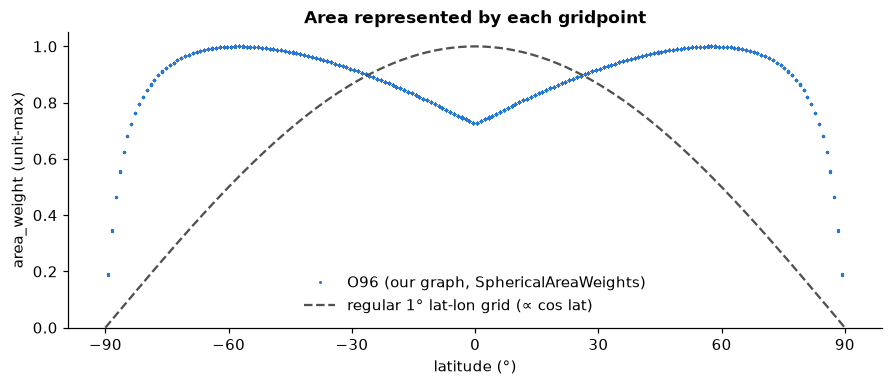

In [11]:
lat_deg = np.rad2deg(graph["data"].x[:, 0].numpy())
fig, ax = plt.subplots(figsize=(8, 3.4), constrained_layout=True)
ax.plot(lat_deg, graph["data"].area_weight.numpy().ravel(), ".", ms=2, color=C_DATA, label="O96 (our graph, SphericalAreaWeights)")
lat_reg = np.linspace(-90, 90, 181)
ax.plot(lat_reg, np.cos(np.deg2rad(lat_reg)), color="#52514e", ls="--", lw=1.5, label="regular 1° lat-lon grid (∝ cos lat)")
ax.set(xlabel="latitude (°)", ylabel="area_weight (unit-max)", xticks=range(-90, 91, 30), ylim=(0, 1.05),
       title="Area represented by each gridpoint")
ax.legend(frameon=False, loc="lower center")
plt.show()

The octahedral O96 grid is close to equal-area: weights stay between about 0.7 and 1, except for the last rows at the poles. On a regular lat-lon grid (dashed) a polar point represents almost no area. Without area weights, the loss would spend most of its attention on the poles.

## 6 · Interactive and 3D views

### What the CLI printed

The background `anemoi-graphs create` should be done by now. Besides saving the graph, the CLI prints a summary table (also available on its own as `anemoi-graphs describe graph.pt`). Note the columns *Isolated Source/Target* (unconnected nodes, almost always a bug) and *Min/Max edges/target*.

In [12]:
cli.wait(timeout=600); cli_log.close()
lines = (OUT / "create.log").read_text().splitlines()
start = next(i for i, l in enumerate(lines) if "Path" in l)
print("\n".join(lines[start:]))
g_cli = torch.load(OUT / "graph_cli.pt", weights_only=False)
print("CLI graph identical to the Python one:",
      all(torch.equal(g_cli[k].edge_index, graph[k].edge_index) for k in graph.edge_types))

📦 Path       : /leonardo_scratch/large/usertrain/a08trd25/aiwcas26/graphs/graph_cli.pt
💽 Size       : 5.6 MiB (5881376)

🪩  Nodes summary

   Nodes name │ Num. nodes │  Attributes │ Attribute dim │ Min. latitude │ Max. latitude │ Min. longitude │ Max. longitude
   ───────────┼────────────┼─────────────┼───────────────┼───────────────┼───────────────┼────────────────┼───────────────
   data       │      40320 │ area_weight │             1 │      -89.2842 │       89.2842 │              0 │          359.1
   hidden     │      10242 │             │             0 │           -90 │            90 │       -178.606 │            180
   ───────────┴────────────┴─────────────┴───────────────┴───────────────┴───────────────┴────────────────┴───────────────


🌐  Edges summary

   Source │ Target │ Num. edges │ Isolated Source │ Isolated Target │ Min edges/target │ Max edges/target │ Attribute dim │                     Attributes
   ───────┼────────┼────────────┼─────────────────┼─────────────────┼──

### `anemoi-graphs inspect`: interactive HTML

anemoi-graphs ships an inspection tool:

```bash
anemoi-graphs inspect $SCRATCH/aiwcas26/graphs/graph.pt $SCRATCH/aiwcas26/graphs/inspect/ [--area=north,west,south,east]
```

It writes into the output folder:

- `graph.html`: an **interactive 3D globe** with all node and edge sets (three.js),
- one 2D plotly map per edge set, e.g. `hidden_to_data.html`, with nodes coloured by how many connections they receive,
- `isolated_nodes.html` if anything is unconnected, and PNG histograms of all attributes.

The same functions live in `anemoi.graphs.plotting`, so we can call them directly. First the 2D plotly view of the decoder over Italy. We crop the graph the same way `--area` does. **Zoom, pan and hover** over the orange nodes:

In [13]:
from anemoi.graphs.plotting.interactive_2d_html import plot_interactive_subgraph_2d
from anemoi.graphs.processors.post_process import SubsetNodesInArea

italy = SubsetNodesInArea(nodes_name=["data", "hidden"], area=(48, 6, 36, 19)).update_graph(graph.clone())
plot_interactive_subgraph_2d(italy, ("hidden", "to", "data"))  # out_file=None → shows the figure inline

### The 3D globe

The 3D view draws every node and edge, so for the full O96 graph the HTML file is about 12 MB. To keep it light we build a **smaller graph with the same recipe**: the O48 dataset from notebook 01 and a level-4 icosahedron. Only two values change, and it builds in about a second.

In [14]:
from copy import deepcopy

from anemoi.graphs.plotting.interactive_3d_html import plot_interactive_graph_3d

small = deepcopy(recipe)
small["nodes"]["data"]["node_builder"] = data_node_builder(
    DATA_DIR / "anemoi" / "aifs-ea-an-oper-0001-mars-o48-1979-19-6h-v6-testset.zarr", 48)
small["nodes"]["hidden"]["node_builder"]["resolution"] = 4
small["edges"][1]["edge_builders"][0]["scale_resolutions"] = 4
small_graph = GraphCreator(DotDict(small)).create()

html_3d = OUT / "graph_3d.html"
plot_interactive_graph_3d(small_graph, out_file=html_3d)
print(f"{html_3d}  ({html_3d.stat().st_size / 1e6:.1f} MB)")

/leonardo_scratch/large/usertrain/a08trd25/aiwcas26/graphs/graph_3d.html  (3.1 MB)


**How to open it.** The page loads three.js and an Earth texture from the internet, so it has to run in **your laptop's browser** (the notebook output is also rendered there):

- **Inline**: run the next cell. In VS Code and JupyterLab the globe appears in the output.
- **In a browser tab** (better, full screen):
  - *VS Code Remote*: `File → Open File…`, paste the path printed above, then right-click the tab or the file → **Download…** and open it locally.
  - *Terminal on your laptop*: `scp <user>@login.leonardo.cineca.it:<path printed above> .` and double-click the file.

**In the viewer**: drag to rotate, scroll to zoom, shift+drag to pan. The left panels toggle node sets and edge sets (try showing only `hidden_to_hidden`) and filter nodes by degree.

In [15]:
from IPython.display import HTML, display

page = html_3d.read_text().replace("&", "&amp;").replace("'", "&#39;")  # escape for srcdoc='...'
display(HTML(f"<iframe srcdoc='{page}' width='100%' height='620' style='border:1px solid #ddd;border-radius:8px'></iframe>"))

## 7 · Try it

Both exercises reuse `recipe` and run in a few seconds.

### Exercise 1: refine the hidden mesh

A refined icosahedron at level *r* has 10·4^r + 2 nodes. Change `RES` below (try 3, 4 and 6) and predict the number of hidden nodes, the number of processor edges, and the maximum number of hops before you run the cell. What happens to the hops?

In [16]:
RES = 4  # ← try 3, 4, 6

mesh_only = {"nodes": {"hidden": deepcopy(recipe["nodes"]["hidden"])},
             "edges": [deepcopy(recipe["edges"][1])]}  # just hidden nodes + processor edges
mesh_only["nodes"]["hidden"]["node_builder"]["resolution"] = RES
mesh_only["edges"][0]["edge_builders"][0]["scale_resolutions"] = RES
g = GraphCreator(DotDict(mesh_only)).create()

n, ei = g["hidden"].num_nodes, g[PROC].edge_index.numpy()
hops = shortest_path(sp.csr_matrix((np.ones(ei.shape[1]), (ei[0], ei[1])), shape=(n, n)), unweighted=True, indices=0)
print(f"r={RES}: {n:,} hidden nodes (10·4^r+2 = {10 * 4**RES + 2:,}), {ei.shape[1]:,} processor edges, "
      f"max hops = {int(hops.max())}")

r=4: 2,562 hidden nodes (10·4^r+2 = 2,562), 20,400 processor edges, max hops = 7


<details>
<summary><b>Solution</b> (click to expand)</summary>

| r | hidden nodes | processor edges | max hops |
|---|---|---|---|
| 3 | 642 | 5 040 | 6 |
| 4 | 2 562 | 20 400 | 7 |
| 5 | 10 242 | 81 840 | 8 |
| 6 | 40 962 | 327 600 | 9 |

- Each level multiplies the nodes, and the edges of the finest level, by about 4. Level *r* alone has 30·4^r undirected edges, stored in both directions, so the total is Σ 60·4^l for l = 1…r.
- With multi-scale edges the hop count grows by only **one per level** (logarithmic in resolution). With finest-level edges only it would roughly double per level.
- At r = 6 the hidden mesh has *more* nodes than the O96 data grid (40 320), so it is no longer a compression. That is why O96 is paired with r = 5 in the default config.
</details>

### Exercise 2: shrink the encoder cutoff

`cutoff_factor` scales the encoder radius. Set it to 0.4, 0.5 and 0.6 and count the **data nodes that no hidden node listens to** (they have no outgoing encoder edge). Their information would never reach the processor. Where are they?

cutoff_factor=0.4: 12,312 of 40,320 data nodes are not connected to any hidden node


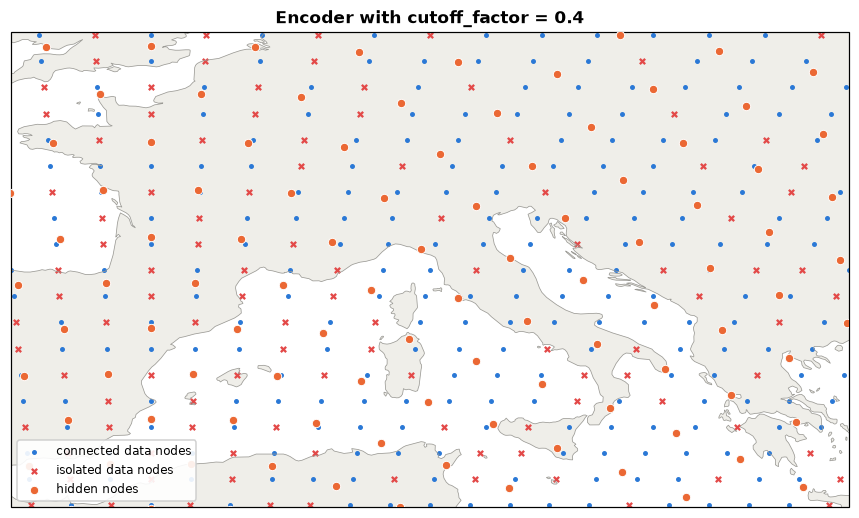

In [17]:
CUTOFF = 0.4  # ← try 0.4, 0.5, 0.6

enc_only = {"nodes": {"data": {"node_builder": recipe["nodes"]["data"]["node_builder"]},
                      "hidden": recipe["nodes"]["hidden"]},
            "edges": [deepcopy(recipe["edges"][0])]}
enc_only["edges"][0]["edge_builders"][0]["cutoff_factor"] = CUTOFF
enc_only["edges"][0]["attributes"] = {}
g = GraphCreator(DotDict(enc_only)).create()

out_deg = np.bincount(g[ENC].edge_index[0].numpy(), minlength=g["data"].num_nodes)
lost = out_deg == 0
print(f"cutoff_factor={CUTOFF}: {lost.sum():,} of {lost.size:,} data nodes are not connected to any hidden node")

fig, ax = plt.subplots(figsize=(8, 4.6), subplot_kw={"projection": ccrs.PlateCarree()}, constrained_layout=True)
ax.set_extent([-5, 25, 35, 52], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#efeee9", edgecolor="none", zorder=0)
ax.coastlines("50m", color="#9b9a95", linewidth=0.5)
ax.scatter(dlon[~lost], dlat[~lost], s=5, color=C_DATA, label="connected data nodes")
ax.scatter(dlon[lost], dlat[lost], s=12, color="#e34948", marker="x", label="isolated data nodes")
ax.scatter(*lonlat(g, "hidden"), s=30, color=C_HIDDEN, edgecolor="white", lw=0.6, label="hidden nodes", zorder=4)
ax.legend(loc="lower left", fontsize=8, framealpha=0.9)
ax.set_title(f"Encoder with cutoff_factor = {CUTOFF}")
plt.show()

<details>
<summary><b>Solution</b> (click to expand)</summary>

- The radius is `cutoff_factor` × (largest nearest-neighbour spacing of the hidden mesh, about 263 km at r = 5).
- The point of the sphere farthest from any hidden node is the centre of a mesh triangle, at about edge length / √3 ≈ 150 km. Any radius below that leaves holes.
- 0.4 (≈ 105 km): 12 312 of 40 320 data nodes are lost, in a regular pattern of triangle centres. 0.5 (≈ 131 km): 1 060 are lost. 0.6 (≈ 158 km): none. That is why the default is 0.6.
- `KNNEdges` cannot leave a *target* without edges, but it can leave *sources* unused. That is why the decoder (every data node must receive a value) uses KNN, and why the CLI summary reports isolated nodes.
</details>

## Summary

- An anemoi model runs on an **encoder–processor–decoder graph**: data nodes (the grid) → hidden nodes (a coarser, multi-scale mesh) → data nodes.
- The graph comes from a **YAML recipe** of node builders, edge builders and attributes, built with `anemoi-graphs create` or `GraphCreator`. In training it is the `graph:` config section, and the default is `graph: multi_scale`, which is what you just built.
- The result is a `torch_geometric` `HeteroData` with coordinates in radians, `edge_index` as (source, target), and attributes such as `edge_length`, `edge_dirs` (model inputs) and `area_weight` (loss weights).
- `anemoi-graphs inspect` and `anemoi.graphs.plotting` provide interactive 2D and 3D views. Use them to check every new graph.

**Next:** in the training notebook this recipe appears as `config.graph`, and `edge_length`/`edge_dirs` appear in `model.attributes.edges`.